In [1]:
%pip -q install sentencepiece datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, random, math, re, unicodedata, json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader
import sentencepiece as spm
from tqdm.auto import tqdm
from datasets import load_dataset
SEED=42
QUICK_RUN=False
DATA_DIR=None
OUT=Path('phomt_bai1_results'); OUT.mkdir(exist_ok=True)
H=256; E=256; LAYERS=3; DROPOUT=.2; VOCAB=16000
BATCH=64; EPOCHS=1 if QUICK_RUN else 10; LR=.001; MAX_LEN=128
PAD=0; UNK=1; BOS=2; EOS=3
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_all():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
seed_all()
print(DEVICE)

cuda


## 1. Đọc dữ liệu và tokenizer (chỉ fit trên train)

In [3]:
from itertools import zip_longest
from datasets import Dataset as HFDataset

def read_local(split):
    root=Path(DATA_DIR)
    candidates=[split, 'valid' if split=='dev' else split, 'validation' if split=='dev' else split]
    for name in candidates:
        for en in root.rglob(name+'.en'):
            vi=en.with_suffix('.vi')
            if vi.exists():
                def rows():
                    with en.open(encoding='utf-8') as a, vi.open(encoding='utf-8') as b:
                        for x,y in zip_longest(a,b):
                            if x is None or y is None: raise ValueError('Parallel files differ in line count')
                            yield {'en':x.strip(),'vi':y.strip()}
                return HFDataset.from_generator(rows)
    raise FileNotFoundError(f'Không tìm thấy cặp file {split}.en / {split}.vi trong {root}')
if DATA_DIR:
    raw={s:read_local(s) for s in ['train','dev','test']}
else:
    ds=load_dataset('ura-hcmut/PhoMT')
    print(ds)
    devkey=next(k for k in ('validation','dev','valid') if k in ds)
    raw={'train':ds['train'],'dev':ds[devkey],'test':ds['test']}
for split, d in raw.items():
    if 'translation' in d.column_names:
        raw[split]=d.map(lambda x:x['translation'],remove_columns=d.column_names)
    assert {'en','vi'}.issubset(raw[split].column_names), raw[split].column_names
    if QUICK_RUN:
        raw[split]=raw[split].shuffle(seed=SEED).select(range(min(len(d), {'train':10000,'dev':500,'test':500}[split])))
    print(split,len(raw[split]),raw[split][0])
def norm(s): return unicodedata.normalize('NFC',s).strip()
sp={}
for lang in ('en','vi'):
    prefix=str(OUT / (('quick_' if QUICK_RUN else 'full_')+lang))
    spm.SentencePieceTrainer.train(sentence_iterator=(norm(r[lang]) for r in raw['train'] if r[lang]), model_prefix=prefix, vocab_size=VOCAB, model_type='bpe', character_coverage=1.0, pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS, hard_vocab_limit=False, input_sentence_size=1000000, shuffle_input_sentence=True)
    sp[lang]=spm.SentencePieceProcessor(model_file=prefix+'.model')
print({k:v.get_piece_size() for k,v in sp.items()})

README.md:   0%|          | 0.00/653 [00:00<?, ?B/s]

PhoMT_training.csv: reconstructing file:   0%|          |  0.00B /  525MB            

PhoMT_training.csv: downloading bytes:           |  0.00B            

PhoMT_validation.csv:   0%|          | 0.00/3.27M [00:00<?, ?B/s]

PhoMT_test.csv:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2977999 [00:00<?, ? examples/s]

... (2 outputs left out)

DatasetDict({
    train: Dataset({
        features: ['en', 'vi'],
        num_rows: 2977999
    })
    validation: Dataset({
        features: ['en', 'vi'],
        num_rows: 18720
    })
    test: Dataset({
        features: ['en', 'vi'],
        num_rows: 19151
    })
})
train 2977999 {'en': 'It begins with a countdown.', 'vi': 'Câu chuyện bắt đầu với buổi lễ đếm ngược.'}
dev 18720 {'en': '\ufeffHurricane Dorian, one of the most powerful storms ever recorded in the Atlantic Ocean, made landfall as a Category 5 storm on Great Abaco Island in the northern Bahamas on Sunday morning, September 1, 2019.', 'vi': 'Vào chủ nhật ngày 1-9-2019, cơn bão Dorian, một trong những cơn bão mạnh nhất được ghi nhận ở Đại Tây Dương, với sức gió 362 km/h đổ bộ vào đảo Great Abaco, miền bắc Bahamas.'}
test 19151 {'en': 'Brother Albert Barnett and his wife, Sister Susan Barnett, from the West Congregation in Tuscaloosa, Alabama', 'vi': 'Anh Albert Barnett và chị Susan Barnett, thuộc hội thánh West ở Tusc

I0000 00:00:1795619987.716417      23 sentencepiece_trainer.cc:105] Starts training with : 
trainer_spec {
  input_format: 
  model_prefix: phomt_bai1_results/full_en
  model_type: BPE
  vocab_size: 16000
  self_test_sample_size: 0
  character_coverage: 1
  input_sentence_size: 1000000
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  required_chars: 
  byte_fallback: 0
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 0
  use_all_vocab: 0
  unk_id: 1
  bos_id: 2
  eos_id: 3
  pad_id: 0
  unk_piece: <unk>
  bos_piece: <s>
  eos_piece: </s>
  pad_piece: <pad>
  unk_surface:  ⁇ 
  enable_different

{'en': 16000, 'vi': 16000}


I0000 00:00:1795620125.308033      23 trainer_interface.cc:702] Saving model: phomt_bai1_results/full_vi.model
I0000 00:00:1795620125.316003      23 trainer_interface.cc:714] Saving vocabs: phomt_bai1_results/full_vi.vocab


In [4]:
# Cache token IDs via Arrow; train/dev bỏ câu quá dài, test giữ toàn bộ và không cắt reference.
def tokenize(batch):
    return {lang+'_ids':[[BOS]+ids+[EOS] for ids in sp[lang].encode([norm(x or '') for x in batch[lang]],out_type=int)] for lang in ('en','vi')}
encoded={}
for split,d in raw.items():
    d=d.map(tokenize,batched=True,batch_size=1024,load_from_cache_file=False)
    if split!='test':
        d=d.filter(lambda x: 2<len(x['en_ids'])<=MAX_LEN and 2<len(x['vi_ids'])<=MAX_LEN)
    encoded[split]=d
    print(split,len(d))

def collate(rows):
    src=[torch.tensor(r['en_ids'],dtype=torch.long) for r in rows]
    tgt=[torch.tensor(r['vi_ids'],dtype=torch.long) for r in rows]
    return pad_sequence(src,batch_first=True,padding_value=PAD),pad_sequence(tgt,batch_first=True,padding_value=PAD),[r['vi'] for r in rows],[r['en'] for r in rows]
def loaders():
    g=torch.Generator().manual_seed(SEED)
    return {s:DataLoader(d,batch_size=BATCH if s!='test' else 32,shuffle=s=='train',generator=g if s=='train' else None,collate_fn=collate,pin_memory=DEVICE.type=='cuda') for s,d in encoded.items()}

Map:   0%|          | 0/2977999 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2977999 [00:00<?, ? examples/s]

train 2972954


Map:   0%|          | 0/18720 [00:00<?, ? examples/s]

Filter:   0%|          | 0/18720 [00:00<?, ? examples/s]

dev 18696


Map:   0%|          | 0/19151 [00:00<?, ? examples/s]

test 19151


## 2. Kiến trúc mô hình — Encoder–Decoder LSTM cơ bản

In [5]:
class Encoder(nn.Module):
    def __init__(self,v):
        super().__init__(); self.emb=nn.Embedding(v,E,padding_idx=PAD); self.drop=nn.Dropout(DROPOUT)
        self.rnn=nn.LSTM(E,H,LAYERS,batch_first=True,dropout=DROPOUT)
    def forward(self,x):
        mask=x.ne(PAD); lengths=mask.sum(1).cpu()
        p=pack_padded_sequence(self.drop(self.emb(x)),lengths,batch_first=True,enforce_sorted=False)
        p,state=self.rnn(p); mem,_=pad_packed_sequence(p,batch_first=True,total_length=x.size(1))
        return mem,state,mask

class VanillaDecoder(nn.Module):
    def __init__(self,v):
        super().__init__(); self.emb=nn.Embedding(v,E,padding_idx=PAD); self.drop=nn.Dropout(DROPOUT)
        self.rnn=nn.LSTM(E,H,LAYERS,batch_first=True,dropout=DROPOUT); self.out=nn.Linear(H,v)
    def step(self,y,state,mem,mask,feed,keys):
        o,state=self.rnn(self.drop(self.emb(y))[:,None,:],state)
        return self.out(o[:,0]),state,feed
    def teacher(self,y,state):
        o,_=self.rnn(self.drop(self.emb(y)),state); return self.out(o)

class Seq2Seq(nn.Module):
    def __init__(self,kind,src_vocab,tgt_vocab):
        super().__init__(); self.kind=kind; self.enc=Encoder(src_vocab)
        self.dec=VanillaDecoder(tgt_vocab)
    def prepare(self,src):
        mem,state,mask=self.enc(src); feed=mem.new_zeros(src.size(0),H)
        keys=None
        return mem,state,mask,feed,keys
    def forward(self,src,tgt_in):
        mem,state,mask,feed,keys=self.prepare(src)
        if self.kind=='vanilla': return self.dec.teacher(tgt_in,state)
        outputs=[]
        for y in tgt_in.unbind(1):
            logits,state,feed=self.dec.step(y,state,mem,mask,feed,keys); outputs.append(logits)
        return torch.stack(outputs,1)
    @torch.no_grad()
    def generate(self,src,max_len=MAX_LEN):
        mem,state,mask,feed,keys=self.prepare(src)
        y=src.new_full((src.size(0),),BOS); done=torch.zeros_like(y,dtype=torch.bool); outputs=[]
        for _ in range(max_len-1):
            logits,state,feed=self.dec.step(y,state,mem,mask,feed,keys)
            logits[:,PAD]=-torch.inf; logits[:,BOS]=-torch.inf
            y=logits.argmax(-1); y=torch.where(done,EOS,y); outputs.append(y); done=done | y.eq(EOS)
            if done.all(): break
        return torch.stack(outputs,1)

## 3. Huấn luyện Adam và chọn checkpoint theo validation loss
Teacher forcing 100% trong train/validation; greedy autoregressive khi test. Cross entropy bỏ PAD. Lưu best checkpoint, lịch sử loss và số tham số. AMP chỉ dùng trên CUDA.

In [6]:
import time
from contextlib import nullcontext

def run_epoch(model,loader,opt=None,scaler=None):
    train=opt is not None; model.train(train); total=0.; tokens=0
    criterion=nn.CrossEntropyLoss(ignore_index=PAD,reduction='sum')
    with torch.set_grad_enabled(train):
        for src,tgt,_,_ in tqdm(loader,leave=False):
            src,tgt=src.to(DEVICE),tgt.to(DEVICE); gold=tgt[:,1:]; count=gold.ne(PAD).sum().item()
            if train: opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=DEVICE.type=='cuda'):
                logits=model(src,tgt[:,:-1]); loss_sum=criterion(logits.reshape(-1,logits.size(-1)),gold.reshape(-1)); loss=loss_sum/count
            if train:
                scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(),1.0)
                scaler.step(opt); scaler.update()
            total+=loss_sum.item(); tokens+=count
    return total/tokens

def make_model(kind): return Seq2Seq(kind,sp['en'].get_piece_size(),sp['vi'].get_piece_size()).to(DEVICE)
MODE='quick' if QUICK_RUN else 'full'
def fit(kind):
    seed_all(); model=make_model(kind); data=loaders(); opt=torch.optim.Adam(model.parameters(),lr=LR)
    scaler=torch.amp.GradScaler('cuda',enabled=DEVICE.type=='cuda'); best=float('inf'); history=[]
    path=OUT/f'{MODE}_{kind}_best.pt'
    for epoch in range(1,EPOCHS+1):
        start=time.time(); tr=run_epoch(model,data['train'],opt,scaler); va=run_epoch(model,data['dev'])
        row={'epoch':epoch,'train_loss':tr,'val_loss':va,'seconds':time.time()-start}; history.append(row); print(kind,row)
        if va<best:
            best=va; torch.save(model.state_dict(),path)
        pd.DataFrame(history).to_csv(OUT/f'{MODE}_{kind}_history.csv',index=False)
    del model
    if DEVICE.type=='cuda': torch.cuda.empty_cache()
    return path

## Huấn luyện

In [7]:
fit('vanilla')

  0%|          | 0/46453 [00:00<?, ?it/s]

  0%|          | 0/293 [00:00<?, ?it/s]

vanilla {'epoch': 1, 'train_loss': 3.941452511553097, 'val_loss': 3.2462675589916596, 'seconds': 2102.088750600815}


  0%|          | 0/46453 [00:00<?, ?it/s]

  0%|          | 0/293 [00:00<?, ?it/s]

vanilla {'epoch': 2, 'train_loss': 3.3162834824540446, 'val_loss': 3.0186636794366732, 'seconds': 2097.877672433853}


... (21 outputs left out)

  0%|          | 0/46453 [00:00<?, ?it/s]

  0%|          | 0/293 [00:00<?, ?it/s]

vanilla {'epoch': 10, 'train_loss': 2.8569999764394027, 'val_loss': 2.6570390752040645, 'seconds': 2108.839742422104}


PosixPath('phomt_bai1_results/full_vanilla_best.pt')

## 4. ROUGE-L trên test
Tính LCS trên token tiếng Việt sau khi decode BPE, chuẩn hóa Unicode NFC, lowercase, tách từ theo khoảng trắng và dấu câu Unicode (không dùng English stemmer). Báo cáo macro-average precision, recall và F1 theo câu. Không dùng teacher forcing khi test. Giới hạn sinh 127 token; reference không bị cắt.

In [8]:
def metric_tokens(s): return re.findall(r"\w+|[^\w\s]",norm(s).lower(),flags=re.UNICODE)
def rouge_l(ref,hyp):
    a,b=metric_tokens(ref),metric_tokens(hyp)
    if not a or not b: return 0.,0.,0.
    prev=[0]*(len(b)+1)
    for x in a:
        cur=[0]
        for j,y in enumerate(b,1): cur.append(prev[j-1]+1 if x==y else max(prev[j],cur[-1]))
        prev=cur
    lcs=prev[-1]; p=lcs/len(b); r=lcs/len(a); return p,r,2*p*r/(p+r) if p+r else 0.
def decode(ids):
    ids=list(ids)
    if EOS in ids: ids=ids[:ids.index(EOS)]
    return sp['vi'].decode([x for x in ids if x not in (PAD,BOS)])
assert rouge_l('tôi đi học','tôi đi học')==(1.,1.,1.)
@torch.no_grad()
def evaluate(kind):
    model=make_model(kind); model.load_state_dict(torch.load(OUT/f'{MODE}_{kind}_best.pt',map_location=DEVICE,weights_only=True)); model.eval()
    records=[]
    for src,_,refs,english in tqdm(loaders()['test']):
        preds=model.generate(src.to(DEVICE)).cpu().tolist()
        for en,ref,ids in zip(english,refs,preds):
            hyp=decode(ids); p,r,f=rouge_l(ref,hyp); records.append(dict(english=en,reference=ref,prediction=hyp,precision=p,recall=r,f1=f))
    df=pd.DataFrame(records); df.to_csv(OUT/f'{MODE}_{kind}_predictions.csv',index=False)
    return {'model':kind,'test_n':len(df),'parameters':sum(p.numel() for p in model.parameters()),'ROUGE-L P':df.precision.mean(),'ROUGE-L R':df.recall.mean(),'ROUGE-L F1':df.f1.mean()}
results=pd.DataFrame([evaluate('vanilla')]); results.to_csv(OUT/f'{MODE}_metrics.csv',index=False); display(results)

  0%|          | 0/599 [00:00<?, ?it/s]

,model,test_n,parameters,ROUGE-L P,ROUGE-L R,ROUGE-L F1
0,vanilla,19151,15462016,0.470932,0.448972,0.455577


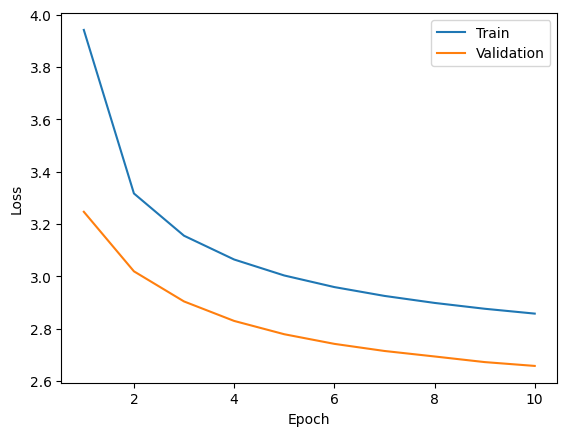

,english,reference,prediction,precision,recall,f1
0,"Brother Albert Barnett and his wife, Sister Su...","Anh Albert Barnett và chị Susan Barnett, thuộc...","Ông Barnes và vợ của tôi, vợ của bà, từ Marche...",0.250000,0.312500,0.277778
1,Severe storms ripped through parts of the sout...,"Ngày 11 và 12-1-2020, những cơn bão lớn đã qué...",Cơn bão đã bị kéo dài qua các vùng lãnh thổ ph...,0.423077,0.366667,0.392857
2,"Two days of heavy rain, high winds, and numero...",Những trận mưa to và gió lớn trong suốt hai ng...,"Hai ngày mưa lớn, mưa, mưa và nhiều cơn bão gâ...",0.500000,0.370370,0.425532
3,"Sadly, Brother Albert Barnett and his wife, Si...","Đáng buồn là anh Albert Barnett 85 tuổi, và vợ...","Đáng buồn, ông James Randy, William Brown và W...",0.216216,0.258065,0.235294
4,The United States branch also reports that at ...,Chi nhánh Hoa Kỳ cũng cho biết có ít nhất bốn ...,Vương quốc Anh cũng nói rằng ít nhất hai anh c...,0.233333,0.250000,0.241379


In [9]:
import matplotlib.pyplot as plt
history=pd.read_csv(OUT/f'{MODE}_vanilla_history.csv')
plt.plot(history.epoch,history.train_loss,label='Train')
plt.plot(history.epoch,history.val_loss,label='Validation')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.show()
display(pd.read_csv(OUT/f'{MODE}_vanilla_predictions.csv').head(5))